<a href="https://colab.research.google.com/github/yusu-source/google_colab/blob/main/itids_2026_llm_judge_branch_calls.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Adaptive Hierarchical LLM-as-a-Judge

Эксперимент для 12 конспектов (`eco_1..4`, `just_1..4`, `math_1..4`) с тремя независимыми судьями:

- Mistral Large 3 — `mistral-large-2512`
- Qwen3.8-Max snapshot — `qwen3.8-max-0902`
- DeepSeek V4 Pro — `deepseek-v4-pro`

Ноутбук:
1. загружает `lectures.zip`;
2. выполняет адаптивное иерархическое анкетирование;
3. делает несколько независимых прогонов;
4. сохраняет сырые ответы API;
5. рассчитывает агрегированные оценки;
6. считает меры межсудейской согласованности и стабильности;
7. экспортирует таблицы в CSV и ZIP.

> **Важно:** полноту и соответствие исходной лекции корректно оценивать только при наличии транскрипта/эталона. Код поддерживает эталоны, но если их нет, reference-зависимые критерии автоматически исключаются.


In [ ]:

!pip -q install -U openai pandas numpy scipy pingouin krippendorff scikit-learn tenacity


## 1. Настройки эксперимента

In [ ]:

from pathlib import Path
import os, json, zipfile, time, math, re
from getpass import getpass

import numpy as np
import pandas as pd

ZIP_PATH = Path("lectures.zip")
WORK_DIR = Path("/content/llm_judge_experiment")
DOC_DIR = WORK_DIR / "documents"
REF_DIR = WORK_DIR / "references"       # необязательно
RAW_DIR = WORK_DIR / "raw_results"
EXPORT_DIR = WORK_DIR / "exports"

for p in [DOC_DIR, REF_DIR, RAW_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Для статьи разумно 3 независимых повтора.
N_REPEATS = 3

# Единые параметры для всех судей.
TEMPERATURE = 0.0
MAX_TOKENS = 1800
SCORE_MIN = 0
SCORE_MAX = 4

# При первом тестовом запуске можно поставить True и обработать только 1 документ.
DEBUG_ONE_DOCUMENT = False

print(WORK_DIR)


/content/llm_judge_experiment



### API-ключи

Ключи вводятся через `getpass`, поэтому они не отображаются в ноутбуке.

Для Qwen современный Alibaba Cloud Model Studio использует региональный/workspace-specific `base_url`.  
Вставьте **полный OpenAI-compatible base URL** из вашей консоли Model Studio.


In [ ]:
from getpass import getpass
from openai import OpenAI

AITUNNEL_API_KEY = getpass("sk-aitunnel")

AITUNNEL_BASE_URL = "https://api.aitunnel.ru/v1/"

MODEL_CONFIG = {
    "mistral": {
        "model": "gemini-3.8-flash",
        "base_url": AITUNNEL_BASE_URL,
        "api_key": AITUNNEL_API_KEY,
        "extra_body": {},
    },

    "qwen": {
        "model": "qwen3.8-max-0902",
        "base_url": AITUNNEL_BASE_URL,
        "api_key": AITUNNEL_API_KEY,
        "extra_body": {},
    },

    "deepseek": {
        "model": "deepseek-v4-pro-0813",
        "base_url": AITUNNEL_BASE_URL,
        "api_key": AITUNNEL_API_KEY,
        "extra_body": {},
    },
}

TEMPERATURE = 0.0
MAX_TOKENS = 1400

SCORE_MIN = 0
SCORE_MAX = 4

N_REPEATS = 3

clients = {
    name: OpenAI(
        api_key=cfg["api_key"],
        base_url=cfg["base_url"],
    )
    for name, cfg in MODEL_CONFIG.items()
}

for name, cfg in MODEL_CONFIG.items():
    print(name, "->", cfg["model"])

sk-aitunnel··········
mistral -> gemini-3.8-flash
qwen -> qwen3.8-max-0902
deepseek -> deepseek-v4-pro-0813


## 2. Распаковка и проверка набора данных

In [ ]:

if not ZIP_PATH.exists():
    from google.colab import files
    print("Загрузите lectures.zip")
    uploaded = files.upload()
    if "lectures.zip" not in uploaded:
        raise FileNotFoundError("Ожидался файл lectures.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DOC_DIR)

documents = sorted(DOC_DIR.glob("*.md"))

def domain_from_name(name: str) -> str:
    if name.startswith("eco_"):
        return "Экология"
    if name.startswith("just_"):
        return "Юриспруденция"
    if name.startswith("math_"):
        return "Математика"
    return "Неизвестно"

manifest = pd.DataFrame([
    {
        "doc_id": p.stem,
        "domain": domain_from_name(p.name),
        "path": str(p),
        "chars": len(p.read_text(encoding="utf-8")),
    }
    for p in documents
])

display(manifest)
assert len(manifest) == 12, f"Ожидалось 12 документов, найдено {len(manifest)}"


,doc_id,domain,path,chars
0,eco_1,Экология,/content/llm_judge_experiment/documents/eco_1.md,12942
1,eco_2,Экология,/content/llm_judge_experiment/documents/eco_2.md,8485
2,eco_3,Экология,/content/llm_judge_experiment/documents/eco_3.md,12980
3,eco_4,Экология,/content/llm_judge_experiment/documents/eco_4.md,12030
4,just_1,Юриспруденция,/content/llm_judge_experiment/documents/just_1.md,8225
5,just_2,Юриспруденция,/content/llm_judge_experiment/documents/just_2.md,7790
6,just_3,Юриспруденция,/content/llm_judge_experiment/documents/just_3.md,9035
7,just_4,Юриспруденция,/content/llm_judge_experiment/documents/just_4.md,7385
8,math_1,Математика,/content/llm_judge_experiment/documents/math_1.md,11249
9,math_2,Математика,/content/llm_judge_experiment/documents/math_2.md,13454



## 3. Иерархическая анкета

Шкала:
- `0` — критерий не выполнен;
- `1` — выражен слабо, существенные недостатки;
- `2` — выполнен частично;
- `3` — в основном выполнен;
- `4` — выполнен полностью.

Если оценка родительского узла ниже `expand_if_below`, раскрываются дочерние вопросы.

Два критерия — **содержательная полнота** и **соответствие исходному материалу** — требуют эталонного текста.  
Если в `/content/llm_judge_experiment/references/` отсутствует файл с тем же именем, они не участвуют в расчёте.


In [ ]:
RUBRIC = {
    "scale": {
        "min": 0,
        "max": 4,

        "anchors": {
            "0": (
                "Критерий практически не выполнен. "
                "Имеются критические недостатки."
            ),

            "1": (
                "Критерий выполнен слабо. "
                "Имеются существенные недостатки, "
                "значительно влияющие на качество."
            ),

            "2": (
                "Критерий выполнен частично. "
                "Основные элементы присутствуют, однако имеется "
                "как минимум один существенный или несколько заметных недостатков."
            ),

            "3": (
                "Критерий выполнен хорошо. "
                "Существенных недостатков нет, однако присутствуют "
                "конкретные недочеты, упрощения или возможности улучшения."
            ),

            "4": (
                "Критерий выполнен практически безупречно. "
                "Содержательно значимые и заметные недостатки не обнаружены. "
                "Оценка 4 не должна использоваться просто для хорошего результата."
            ),
        }
    },

    "roots": [

        # =========================================================
        # 1. ПОЛНОТА РАСКРЫТИЯ ТЕМЫ
        # =========================================================
        {
            "id": "topic_completeness",

            "question": (
                "Насколько полно конспект раскрывает рассматриваемую тему "
                "с учетом ключевых понятий, положений, связей и выводов "
                "предметной области?"
            ),

            "weight": 0.30,

            # Первый уровень раскрываем ВСЕГДА
            "always_expand": True,

            "requires_reference": False,

            "children": [

                {
                    "id": "key_ideas",

                    "question": (
                        "Представлены ли основные идеи и положения, "
                        "необходимые для раскрытия рассматриваемой темы?"
                    ),

                    "weight": 0.25,

                    # Второй → третий уровень уже адаптивный
                    "expand_if_below": 3,

                    "children": [
                        {
                            "id": "core_coverage",
                            "question": (
                                "Охвачены ли центральные положения темы, "
                                "без которых ее понимание было бы неполным?"
                            ),
                            "weight": 0.60,
                        },

                        {
                            "id": "focus_balance",
                            "question": (
                                "Не смещен ли акцент на второстепенные детали "
                                "в ущерб основным положениям?"
                            ),
                            "weight": 0.40,
                        }
                    ],
                },

                {
                    "id": "definitions",

                    "question": (
                        "Раскрыты ли ключевые понятия и определения, "
                        "необходимые для понимания темы?"
                    ),

                    "weight": 0.20,
                },

                {
                    "id": "concept_relations",

                    "question": (
                        "Показаны ли существенные логические связи "
                        "между понятиями и положениями?"
                    ),

                    "weight": 0.20,

                    "expand_if_below": 3,

                    "children": [
                        {
                            "id": "explicit_relations",
                            "question": (
                                "Показано ли, каким образом основные понятия "
                                "связаны друг с другом?"
                            ),
                            "weight": 0.50,
                        },

                        {
                            "id": "conditions_dependencies",
                            "question": (
                                "Сохранены ли существенные условия, зависимости "
                                "и ограничения между рассматриваемыми положениями?"
                            ),
                            "weight": 0.50,
                        }
                    ],
                },

                {
                    "id": "supporting_elements",

                    "question": (
                        "Представлены ли необходимые для данной темы примеры, "
                        "формулы, нормы, доказательства или иные поясняющие элементы? "
                        "Не снижать оценку за отсутствие элемента, "
                        "если для данной темы он объективно не требуется."
                    ),

                    "weight": 0.15,
                },

                {
                    "id": "conclusions",

                    "question": (
                        "Сформулированы ли основные выводы "
                        "по рассматриваемой теме?"
                    ),

                    "weight": 0.10,
                },

                {
                    "id": "topic_gaps",

                    "question": (
                        "Отсутствуют ли существенные тематические пробелы, "
                        "мешающие целостному пониманию материала?"
                    ),

                    "weight": 0.10,
                },
            ],
        },

        # =========================================================
        # 2. ФАКТИЧЕСКАЯ И ПРЕДМЕТНАЯ КОРРЕКТНОСТЬ
        # =========================================================
        {
            "id": "factual_correctness",

            "question": (
                "Насколько фактически и предметно корректно "
                "изложен материал конспекта?"
            ),

            "weight": 0.25,

            "always_expand": True,

            "requires_reference": False,

            "children": [

                {
                    "id": "terminology_accuracy",

                    "question": (
                        "Корректно ли используется терминология "
                        "соответствующей предметной области?"
                    ),

                    "weight": 0.25,
                },

                {
                    "id": "fact_accuracy",

                    "question": (
                        "Корректны ли фактические утверждения, "
                        "числовые значения, формулы, нормы и иные проверяемые сведения?"
                    ),

                    "weight": 0.30,

                    "expand_if_below": 3,

                    "children": [
                        {
                            "id": "statements_correctness",

                            "question": (
                                "Отсутствуют ли предметно ошибочные "
                                "или вводящие в заблуждение утверждения?"
                            ),

                            "weight": 0.60,
                        },

                        {
                            "id": "formal_correctness",

                            "question": (
                                "Корректны ли числовые значения, формулы, "
                                "обозначения, ссылки на нормы или иные "
                                "формализованные элементы, если они присутствуют?"
                            ),

                            "weight": 0.40,
                        },
                    ],
                },

                {
                    "id": "logic_accuracy",

                    "question": (
                        "Корректны ли логические выводы, зависимости "
                        "и причинно-следственные связи?"
                    ),

                    "weight": 0.25,
                },

                {
                    "id": "unsupported_claims",

                    "question": (
                        "Отсутствуют ли предметно необоснованные, "
                        "ложные или противоречащие общепринятым знаниям утверждения?"
                    ),

                    "weight": 0.20,
                },
            ],
        },

        # =========================================================
        # 3. СТРУКТУРНАЯ КОРРЕКТНОСТЬ
        # =========================================================
        {
            "id": "structure",

            "question": (
                "Насколько корректно и логично "
                "организована структура конспекта?"
            ),

            "weight": 0.25,

            "always_expand": True,

            "requires_reference": False,

            "children": [

                {
                    "id": "hierarchy",

                    "question": (
                        "Корректна ли иерархия разделов, подразделов "
                        "и смысловых элементов?"
                    ),

                    "weight": 0.30,

                    "expand_if_below": 3,

                    "children": [
                        {
                            "id": "heading_hierarchy",

                            "question": (
                                "Соответствуют ли уровни заголовков "
                                "логической вложенности материала?"
                            ),

                            "weight": 0.50,
                        },

                        {
                            "id": "section_assignment",

                            "question": (
                                "Корректно ли содержание распределено "
                                "между соответствующими разделами?"
                            ),

                            "weight": 0.50,
                        },
                    ],
                },

                {
                    "id": "sequence",

                    "question": (
                        "Логична ли последовательность изложения материала?"
                    ),

                    "weight": 0.30,

                    "expand_if_below": 3,

                    "children": [
                        {
                            "id": "prerequisite_order",

                            "question": (
                                "Предшествуют ли необходимые определения "
                                "и положения тем элементам, которые на них опираются?"
                            ),

                            "weight": 0.50,
                        },

                        {
                            "id": "transitions",

                            "question": (
                                "Являются ли переходы между смысловыми блоками "
                                "последовательными и логичными?"
                            ),

                            "weight": 0.50,
                        },
                    ],
                },

                {
                    "id": "segmentation",

                    "question": (
                        "Адекватно ли материал разделен "
                        "на самостоятельные смысловые блоки?"
                    ),

                    "weight": 0.20,
                },

                {
                    "id": "navigation",

                    "question": (
                        "Позволяет ли структура документа быстро находить "
                        "нужные элементы и понимать общую организацию материала?"
                    ),

                    "weight": 0.20,
                },
            ],
        },

        # =========================================================
        # 4. КАЧЕСТВО ПРЕДСТАВЛЕНИЯ
        # =========================================================
        {
            "id": "presentation",

            "question": (
                "Насколько качественно материал представлен "
                "как структурированный учебный конспект?"
            ),

            "weight": 0.20,

            "always_expand": True,

            "requires_reference": False,

            "children": [

                {
                    "id": "coherence",

                    "question": (
                        "Является ли изложение связным "
                        "и внутренне непротиворечивым?"
                    ),

                    "weight": 0.30,
                },

                {
                    "id": "readability",

                    "question": (
                        "Насколько текст понятен, однозначен "
                        "и удобен для изучения?"
                    ),

                    "weight": 0.25,
                },

                {
                    "id": "redundancy",

                    "question": (
                        "Отсутствуют ли избыточные повторы "
                        "и информационный шум?"
                    ),

                    "weight": 0.20,

                    "expand_if_below": 3,

                    "children": [
                        {
                            "id": "repeated_content",

                            "question": (
                                "Отсутствуют ли повторяющиеся смысловые блоки, "
                                "не добавляющие новой информации?"
                            ),

                            "weight": 0.50,
                        },

                        {
                            "id": "filler",

                            "question": (
                                "Отсутствуют ли фрагменты, "
                                "не выполняющие содержательной функции?"
                            ),

                            "weight": 0.50,
                        },
                    ],
                },

                {
                    "id": "academic_style",

                    "question": (
                        "Соответствует ли способ изложения "
                        "учебно-академическому назначению конспекта?"
                    ),

                    "weight": 0.25,
                },
            ],
        },
    ],
}

with open(WORK_DIR / "rubric_v2.json", "w", encoding="utf-8") as f:
    json.dump(
        RUBRIC,
        f,
        ensure_ascii=False,
        indent=2,
    )


## 4. Унифицированная инструкция судьи (Skill)

In [ ]:
SYSTEM_SKILL = """
Ты являешься независимым LLM-судьей,
оценивающим структурированный учебный конспект.

Твоя задача — выявлять конкретные достоинства и недостатки документа,
а затем присваивать оценку строго по заданной шкале.

ПРАВИЛА ОЦЕНИВАНИЯ

1. Для каждого критерия сначала найди конкретные недостатки,
относящиеся именно к этому критерию.

2. После выявления недостатков оцени их существенность
и только после этого назначай балл.

3. Используй исключительно значения:
0, 1, 2, 3 или 4.

4. Оценка 3 означает хороший результат,
в котором имеются конкретные небольшие недостатки
или возможности улучшения.

5. Оценка 4 является максимальной.
Используй ее только тогда, когда содержательно значимых
и заметных недостатков по данному критерию не обнаружено.

6. Не выставляй 4 просто потому,
что текст выглядит качественным или профессиональным.

7. Не повышай оценку из-за:
- большого объема текста;
- большого количества заголовков;
- сложной терминологии;
- стилистической гладкости;
- уверенного тона;
- красивого форматирования.

8. Не снижай оценку искусственно.
Если существенных и заметных недостатков действительно нет,
оценка 4 допустима.

9. При оценке тематической полноты и предметной корректности
используй свои знания соответствующей предметной области.

10. Не требуй наличия формул, примеров, нормативных актов
или иных специальных элементов,
если они объективно не требуются для раскрытия данной темы.

11. Не пытайся определить автора документа
или модель, которая могла его создать.

12. Порядок критериев не означает их приоритет.

13. Обоснование должно содержать конкретное наблюдение,
а не общую характеристику вида "все хорошо".

14. Обоснование каждого критерия:
не более 20 слов.

15. Верни только данные,
соответствующие переданной JSON Schema:
{
  "evaluations": [
    {
      "id": "criterion_id",
      "score": 0,
      "reason": "краткое обоснование"
    }
  ]
}
"""


## 5. API-клиенты и вызов судьи

In [ ]:
from openai import OpenAI
from tenacity import retry, stop_after_attempt, wait_exponential

clients = {
    name: OpenAI(api_key=cfg["api_key"], base_url=cfg["base_url"])
    for name, cfg in MODEL_CONFIG.items()
}


def flatten_branch(node, depth=0, parent_id=None):
    """Преобразует одну ветвь рубрики в плоский список для JSON Schema."""
    rows = [{
        "id": node["id"],
        "question": node["question"],
        "depth": depth,
        "parent_id": parent_id,
    }]

    for child in node.get("children", []):
        rows.extend(
            flatten_branch(
                child,
                depth=depth + 1,
                parent_id=node["id"],
            )
        )

    return rows


def prompt_tree(node):
    """Компактное представление дерева для промпта."""
    item = {
        "id": node["id"],
        "question": node["question"],
    }

    children = node.get("children", [])
    if children:
        item["children"] = [prompt_tree(child) for child in children]

    return item


def build_user_prompt(
    document_text,
    root_node,
    reference_text=None,
):
    tree_payload = prompt_tree(root_node)

    return f"""
Оцени одну ветвь критериев качества учебного конспекта.

ВАЖНО:
- оцени ВСЕ узлы переданного дерева: основной критерий, дочерние и внучатые критерии;
- каждый узел оцени самостоятельно по шкале 0..4;
- оценки дочерних критериев не вычисляй из оценки родителя;
- даже если дочерний критерий кажется избыточным, всё равно верни для него оценку;
- для каждого id верни ровно одну запись;
- reason должен быть конкретным и не длиннее 20 слов.

ШКАЛА:

{json.dumps(
    RUBRIC["scale"],
    ensure_ascii=False,
    indent=2
)}

ДЕРЕВО КРИТЕРИЕВ:

{json.dumps(
    tree_payload,
    ensure_ascii=False,
    indent=2
)}

Перед выставлением каждого балла:
1. Найди конкретный недостаток или установи его отсутствие.
2. Оцени существенность недостатка.
3. Выбери только 0, 1, 2, 3 или 4.
4. Не используй 4 как синоним слова "хорошо".

ОЦЕНИВАЕМЫЙ КОНСПЕКТ:

<document>
{document_text}
</document>

Верни только JSON с массивом evaluations.
"""


def validate_eval_payload(payload, branch_nodes):
    if "evaluations" not in payload or not isinstance(payload["evaluations"], list):
        raise ValueError("Нет массива evaluations")

    expected = {n["id"] for n in branch_nodes}
    got = {x.get("id") for x in payload["evaluations"]}

    if expected != got:
        missing = expected - got
        extra = got - expected
        raise ValueError(
            f"Некорректный набор id. missing={missing}, extra={extra}"
        )

    if len(payload["evaluations"]) != len(expected):
        raise ValueError("Есть повторяющиеся id в evaluations")

    for x in payload["evaluations"]:
        score = x.get("score")

        if not isinstance(score, (int, float)):
            raise ValueError(f"Некорректный score: {score}")

        if not (SCORE_MIN <= score <= SCORE_MAX):
            raise ValueError(f"score вне диапазона 0..4: {score}")

        x["score"] = float(score)
        x["reason"] = str(x.get("reason", "")).strip()

    return payload


def make_response_schema(branch_nodes):
    ids = [node["id"] for node in branch_nodes]

    return {
        "type": "json_schema",
        "json_schema": {
            "name": "judge_branch_evaluation",
            "strict": True,
            "schema": {
                "type": "object",
                "properties": {
                    "evaluations": {
                        "type": "array",
                        "minItems": len(branch_nodes),
                        "maxItems": len(branch_nodes),
                        "items": {
                            "type": "object",
                            "properties": {
                                "id": {
                                    "type": "string",
                                    "enum": ids,
                                },
                                "score": {
                                    "type": "integer",
                                    "enum": [0, 1, 2, 3, 4],
                                },
                                "reason": {
                                    "type": "string",
                                },
                            },
                            "required": ["id", "score", "reason"],
                            "additionalProperties": False,
                        },
                    }
                },
                "required": ["evaluations"],
                "additionalProperties": False,
            },
        },
    }


@retry(
    stop=stop_after_attempt(3),
    wait=wait_exponential(multiplier=1, min=2, max=10),
    reraise=True,
)
def call_judge(
    judge_name,
    document_text,
    root_node,
    reference_text=None,
):
    cfg = MODEL_CONFIG[judge_name]
    client = clients[judge_name]

    branch_nodes = flatten_branch(root_node)

    response = client.chat.completions.create(
        model=cfg["model"],
        messages=[
            {
                "role": "system",
                "content": SYSTEM_SKILL,
            },
            {
                "role": "user",
                "content": build_user_prompt(
                    document_text=document_text,
                    root_node=root_node,
                    reference_text=reference_text,
                ),
            },
        ],
        temperature=TEMPERATURE,
        max_tokens=MAX_TOKENS,
        response_format=make_response_schema(branch_nodes),
    )

    choice = response.choices[0]
    finish_reason = choice.finish_reason
    text = choice.message.content

    usage = getattr(response, "usage", None)
    usage_data = {
        "prompt_tokens": getattr(usage, "prompt_tokens", np.nan) if usage else np.nan,
        "completion_tokens": getattr(usage, "completion_tokens", np.nan) if usage else np.nan,
        "total_tokens": getattr(usage, "total_tokens", np.nan) if usage else np.nan,
    }

    # Сначала показываем диагностическую информацию:
    # при reasoning-моделях content иногда пустой именно из-за лимита.
    if not text:
        raise ValueError(
            f"{judge_name}: пустой ответ; "
            f"finish_reason={finish_reason}; usage={usage_data}"
        )

    if finish_reason == "length":
        raise ValueError(
            f"{judge_name}: ответ обрезан по max_tokens={MAX_TOKENS}; "
            f"usage={usage_data}"
        )

    try:
        payload = json.loads(text)
    except json.JSONDecodeError as error:
        print("\nINVALID JSON")
        print("Judge:", judge_name)
        print("Model:", cfg["model"])
        print("finish_reason:", finish_reason)
        print("usage:", usage_data)
        print("\nПоследние 500 символов:\n", text[-500:])

        raise ValueError(
            f"{judge_name}: invalid JSON"
        ) from error

    payload = validate_eval_payload(payload, branch_nodes)

    return {
        "payload": payload,
        "returned_model": getattr(response, "model", None),
        "finish_reason": finish_reason,
        "usage": usage_data,
    }


## 6. Адаптивный обход дерева

In [ ]:
def reference_for_document(doc_path: Path):
    candidate = REF_DIR / doc_path.name
    if candidate.exists():
        return candidate.read_text(encoding="utf-8")
    return None


def applicable_roots(reference_text=None):
    return RUBRIC["roots"]


def normalize_score(score):
    return (
        float(score) - SCORE_MIN
    ) / (
        SCORE_MAX - SCORE_MIN
    )


MAX_TREE_DEPTH = 2


def evaluate_branch(
    judge_name,
    document_text,
    root_node,
    reference_text=None,
):
    """
    Одна верхнеуровневая ветвь = один API-вызов.

    Судья сразу оценивает root + children + grandchildren.
    После этого expand_if_below применяется локально:
    дополнительных API-вызовов больше нет.
    """

    result = call_judge(
        judge_name=judge_name,
        document_text=document_text,
        root_node=root_node,
        reference_text=reference_text,
    )

    by_id = {
        item["id"]: item
        for item in result["payload"]["evaluations"]
    }

    flat_rows = []

    def build_node_result(
        node,
        path_prefix="",
        depth=0,
    ):
        item = by_id[node["id"]]

        raw_score = float(item["score"])
        own_norm = normalize_score(raw_score)

        children = node.get("children", [])

        threshold = node.get(
            "expand_if_below",
            None,
        )

        always_expand = node.get(
            "always_expand",
            False,
        )

        should_expand = bool(
            children
            and depth < MAX_TREE_DEPTH
            and (
                always_expand
                or (
                    threshold is not None
                    and raw_score < threshold
                )
            )
        )

        child_results = []

        if should_expand:
            for child in children:
                child_results.append(
                    build_node_result(
                        child,
                        path_prefix=f"{path_prefix}/{node['id']}",
                        depth=depth + 1,
                    )
                )

            weights = np.array(
                [
                    float(child.get("weight", 1.0))
                    for child in children
                ],
                dtype=float,
            )

            weights = weights / weights.sum()

            final_score = float(
                np.sum(
                    [
                        weight * child_result["final_score"]
                        for weight, child_result
                        in zip(weights, child_results)
                    ]
                )
            )

        else:
            final_score = own_norm

        current = {
            "id": node["id"],
            "question": node["question"],
            "raw_score": raw_score,
            "normalized_own_score": own_norm,
            "final_score": final_score,
            "reason": item["reason"],
            "expanded": should_expand,
            "depth": depth,
            "children": child_results,
        }

        flat_rows.append({
            "node_id": node["id"],
            "path": (
                f"{path_prefix}/{node['id']}"
            ).lstrip("/"),
            "depth": depth,
            "raw_score": raw_score,
            "normalized_own_score": own_norm,
            "final_score": final_score,
            "expanded": should_expand,
            "reason": item["reason"],
        })

        return current

    root_result = build_node_result(root_node)

    return (
        root_result,
        flat_rows,
        result["usage"],
    )


def evaluate_document(judge_name, doc_path: Path, run_id: int):
    document_text = doc_path.read_text(encoding="utf-8")
    reference_text = reference_for_document(doc_path)
    roots = applicable_roots(reference_text)

    if not roots:
        raise RuntimeError("Нет применимых корневых критериев")

    node_results = []
    flat_rows = []
    usage_rows = []

    # Четыре верхнеуровневых критерия -> четыре API-вызова.
    # Документ больше не пересылается отдельно для каждого уровня дерева.
    for root in roots:
        root_result, branch_flat_rows, branch_usage = evaluate_branch(
            judge_name=judge_name,
            document_text=document_text,
            root_node=root,
            reference_text=reference_text,
        )

        node_results.append(root_result)
        flat_rows.extend(branch_flat_rows)
        usage_rows.append(branch_usage)

    root_weights = np.array(
        [float(r["weight"]) for r in roots],
        dtype=float,
    )
    root_weights = root_weights / root_weights.sum()

    overall = float(
        np.sum(
            [
                weight * node_result["final_score"]
                for weight, node_result
                in zip(root_weights, node_results)
            ]
        )
    )

    total_usage = {}

    for field in [
        "prompt_tokens",
        "completion_tokens",
        "total_tokens",
    ]:
        vals = [
            usage.get(field, np.nan)
            for usage in usage_rows
        ]

        total_usage[field] = (
            float(np.nansum(vals))
            if not np.all(pd.isna(vals))
            else np.nan
        )

    output = {
        "doc_id": doc_path.stem,
        "domain": domain_from_name(doc_path.name),
        "judge": judge_name,
        "requested_model": MODEL_CONFIG[judge_name]["model"],
        "run": run_id,
        "reference_used": reference_text is not None,
        "overall_score": overall,
        "criteria": node_results,
        "usage": total_usage,
        "api_calls": len(usage_rows),
        "timestamp_unix": time.time(),
    }

    return output, flat_rows


## 7. Тест одного запроса перед полным экспериментом

In [ ]:

# Сначала лучше проверить один документ и одного судью.
test_doc = documents[0]

test_result, test_nodes = evaluate_document(
    "qwen",
    test_doc,
    run_id=0,
)

print(
    "Document:",
    test_result["doc_id"]
)

print(
    "Overall:",
    test_result["overall_score"]
)

print(
    "API calls:",
    test_result["api_calls"]
)

test_df = pd.DataFrame(
    test_nodes
)

display(
    test_df[
        [
            "path",
            "depth",
            "raw_score",
            "final_score",
            "expanded",
        ]
    ]
)


## 8. Полный эксперимент: 12 документов × 3 судьи × N повторов

In [ ]:

EXPERIMENT_VERSION = "v3_branch_single_call"

all_results = []
all_node_rows = []

docs_to_run = documents[:1] if DEBUG_ONE_DOCUMENT else documents

for run_id in range(1, N_REPEATS + 1):
    for doc_path in docs_to_run:
        for judge_name in MODEL_CONFIG:
            out_path = RAW_DIR / (
                f"{EXPERIMENT_VERSION}"
                f"__{doc_path.stem}"
                f"__{judge_name}"
                f"__run{run_id}.json"
            )

            # Возобновляемый эксперимент: если результат уже есть, не платим второй раз.
            if out_path.exists():
                result = json.loads(out_path.read_text(encoding="utf-8"))
                print("SKIP", out_path.name)

                # Восстановим flattened rows из сохраненного дерева.
                def flatten_saved(nodes, prefix=""):
                    rows = []
                    for n in nodes:
                        path = f"{prefix}/{n['id']}".lstrip("/")
                        rows.append({
                            "node_id": n["id"],
                            "path": path,
                            "depth": n["depth"],
                            "raw_score": n["raw_score"],
                            "normalized_own_score": n["normalized_own_score"],
                            "final_score": n["final_score"],
                            "expanded": n["expanded"],
                            "reason": n["reason"],
                        })
                        rows.extend(flatten_saved(n.get("children", []), path))
                    return rows

                flat_rows = flatten_saved(result["criteria"])
            else:
                print(f"RUN {run_id}/{N_REPEATS}: {doc_path.stem} × {judge_name}")
                result, flat_rows = evaluate_document(judge_name, doc_path, run_id)

                result["experiment_version"] = (
                    EXPERIMENT_VERSION
                )

                out_path.write_text(
                    json.dumps(result, ensure_ascii=False, indent=2),
                    encoding="utf-8"
                )

            all_results.append(result)

            for row in flat_rows:
                row.update({
                    "doc_id": result["doc_id"],
                    "domain": result["domain"],
                    "judge": result["judge"],
                    "run": result["run"],
                    "reference_used": result["reference_used"],
                })
                all_node_rows.append(row)

overall_df = pd.DataFrame([
    {
        "doc_id": r["doc_id"],
        "domain": r["domain"],
        "judge": r["judge"],
        "requested_model": r["requested_model"],
        "run": r["run"],
        "reference_used": r["reference_used"],
        "overall_score": r["overall_score"],
        "api_calls": r["api_calls"],
        **r["usage"],
    }
    for r in all_results
])

nodes_df = pd.DataFrame(all_node_rows)

display(overall_df.head())
display(nodes_df.head())


## 9. Итоговые оценки по документам

In [ ]:

# Повторы одной модели не считаем независимыми судьями:
# сначала усредняем повторы внутри модели.
judge_means = (
    overall_df
    .groupby(["doc_id", "domain", "judge"], as_index=False)
    ["overall_score"].mean()
    .rename(columns={"overall_score": "judge_mean_score"})
)

ensemble_summary = (
    judge_means
    .groupby(["doc_id", "domain"])["judge_mean_score"]
    .agg(["mean", "median", "std", "min", "max", "count"])
    .reset_index()
)

ensemble_summary["range"] = ensemble_summary["max"] - ensemble_summary["min"]
ensemble_summary["cv_percent"] = (
    100 * ensemble_summary["std"] / ensemble_summary["mean"]
)
ensemble_summary = ensemble_summary.rename(columns={
    "mean": "ensemble_mean",
    "median": "ensemble_median",
    "std": "between_judges_sd",
    "min": "judge_min",
    "max": "judge_max",
    "count": "n_judges",
})

display(ensemble_summary.sort_values(["domain", "doc_id"]))


,doc_id,domain,ensemble_mean,ensemble_median,between_judges_sd,judge_min,judge_max,n_judges,range,cv_percent
8,math_1,Математика,0.944444,1.000000,0.096225,0.833333,1.0,3,0.166667,10.188534
9,math_2,Математика,1.000000,1.000000,0.000000,1.000000,1.0,3,0.000000,0.000000
10,math_3,Математика,0.947531,0.962963,0.061651,0.879630,1.0,3,0.120370,6.506510
11,math_4,Математика,1.000000,1.000000,0.000000,1.000000,1.0,3,0.000000,0.000000
0,eco_1,Экология,0.895062,0.888889,0.101992,0.796296,1.0,3,0.203704,11.394974
1,eco_2,Экология,1.000000,1.000000,0.000000,1.000000,1.0,3,0.000000,0.000000
2,eco_3,Экология,1.000000,1.000000,0.000000,1.000000,1.0,3,0.000000,0.000000
3,eco_4,Экология,1.000000,1.000000,0.000000,1.000000,1.0,3,0.000000,0.000000
4,just_1,Юриспруденция,1.000000,1.000000,0.000000,1.000000,1.0,3,0.000000,0.000000
5,just_2,Юриспруденция,1.000000,1.000000,0.000000,1.000000,1.0,3,0.000000,0.000000


## 10. Межсудейская согласованность

In [ ]:

import pingouin as pg
import krippendorff
from scipy.stats import rankdata, pearsonr, spearmanr, friedmanchisquare
from sklearn.metrics import mean_absolute_error, mean_squared_error

def kendalls_w(matrix):
    """
    Kendall's W для n объектов × m судей.
    Учитывается поправка на совпадающие ранги.
    """
    x = np.asarray(matrix, dtype=float)
    n, m = x.shape
    ranks = np.column_stack([
        rankdata(x[:, j], method="average")
        for j in range(m)
    ])

    R = ranks.sum(axis=1)
    S = np.sum((R - R.mean()) ** 2)

    tie_sum = 0.0
    for j in range(m):
        _, counts = np.unique(x[:, j], return_counts=True)
        tie_sum += np.sum(counts**3 - counts)

    denom = m**2 * (n**3 - n) - m * tie_sum
    return float(12 * S / denom) if denom > 0 else np.nan

pivot = judge_means.pivot(
    index="doc_id",
    columns="judge",
    values="judge_mean_score"
).dropna()

display(pivot)

# ICC: absolute agreement.
icc_input = judge_means.rename(columns={
    "doc_id": "target",
    "judge": "rater",
    "judge_mean_score": "rating",
})

icc = pg.intraclass_corr(
    data=icc_input,
    targets="target",
    raters="rater",
    ratings="rating",
)

icc_selected = icc[icc["Type"].isin(["ICC2", "ICC2k"])]
display(icc_selected)

# Krippendorff alpha для непрерывной нормированной оценки.
alpha_interval = krippendorff.alpha(
    reliability_data=pivot.T.to_numpy(),
    level_of_measurement="interval",
)

# Kendall W: насколько одинаково модели ранжируют 12 документов.
kendall_w = kendalls_w(pivot.to_numpy())

print("Krippendorff alpha (interval):", round(alpha_interval, 4))
print("Kendall W:", round(kendall_w, 4))


judge,deepseek,mistral,qwen
doc_id,,,
eco_1,0.888889,1.0,0.796296
eco_2,1.000000,1.0,1.000000
eco_3,1.000000,1.0,1.000000
eco_4,1.000000,1.0,1.000000
just_1,1.000000,1.0,1.000000
just_2,1.000000,1.0,1.000000
just_3,1.000000,1.0,1.000000
just_4,1.000000,1.0,1.000000
math_1,1.000000,1.0,0.833333


,Type,ICC,F,df1,df2,pval,CI95


Krippendorff alpha (interval): 0.2056
Kendall W: 0.5796


## 11. Попарное сравнение судей

In [ ]:

from itertools import combinations

pair_rows = []

for a, b in combinations(pivot.columns, 2):
    x = pivot[a].to_numpy()
    y = pivot[b].to_numpy()

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_rho, spearman_p = spearmanr(x, y)

    pair_rows.append({
        "judge_a": a,
        "judge_b": b,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_rho": spearman_rho,
        "spearman_p": spearman_p,
        "MAE": mean_absolute_error(x, y),
        "RMSE": math.sqrt(mean_squared_error(x, y)),
        "mean_signed_difference_a_minus_b": float(np.mean(x - y)),
    })

pairwise_df = pd.DataFrame(pair_rows)
display(pairwise_df)


/tmp/ipykernel_16192/1665404418.py:9: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson_r, pearson_p = pearsonr(x, y)
/tmp/ipykernel_16192/1665404418.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho, spearman_p = spearmanr(x, y)
/tmp/ipykernel_16192/1665404418.py:9: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  pearson_r, pearson_p = pearsonr(x, y)
/tmp/ipykernel_16192/1665404418.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_rho, spearman_p = spearmanr(x, y)


,judge_a,judge_b,pearson_r,pearson_p,spearman_rho,spearman_p,MAE,RMSE,mean_signed_difference_a_minus_b
0,deepseek,mistral,NaN,NaN,NaN,NaN,0.019290,0.047289,-0.019290
1,deepseek,qwen,0.539505,0.070244,0.747927,0.005154,0.028549,0.060066,0.014660
2,mistral,qwen,NaN,NaN,NaN,NaN,0.033951,0.076727,0.033951


## 12. Есть ли систематическая разница между судьями?

In [ ]:

# Непараметрический парный тест: документы являются блоками,
# три модели — повторными условиями.
judge_cols = list(pivot.columns)
friedman = friedmanchisquare(*[pivot[c].to_numpy() for c in judge_cols])

print("Friedman chi-square:", friedman.statistic)
print("p-value:", friedman.pvalue)

judge_level = (
    judge_means.groupby("judge")["judge_mean_score"]
    .agg(["mean", "std", "median", "min", "max"])
    .reset_index()
)
display(judge_level)


Friedman chi-square: 3.818181818181819
p-value: 0.14821506633752013


,judge,mean,std,median,min,max
0,deepseek,0.980710,0.045095,1.0,0.879630,1.0
1,mistral,1.000000,0.000000,1.0,1.000000,1.0
2,qwen,0.966049,0.071867,1.0,0.796296,1.0


## 13. Стабильность одной модели между повторными запусками

In [ ]:

within_rows = []

for judge, sub in overall_df.groupby("judge"):
    per_doc = (
        sub.groupby("doc_id")["overall_score"]
        .agg(["mean", "std", "min", "max"])
    )
    per_doc["range"] = per_doc["max"] - per_doc["min"]

    # ICC между повторными прогонами модели.
    tmp = sub.rename(columns={
        "doc_id": "target",
        "run": "rater",
        "overall_score": "rating",
    })[["target", "rater", "rating"]]

    icc_runs = pg.intraclass_corr(
        data=tmp,
        targets="target",
        raters="rater",
        ratings="rating"
    )

    icc2 = icc_runs.loc[icc_runs["Type"] == "ICC2", "ICC"].iloc[0]
    icc2k = icc_runs.loc[icc_runs["Type"] == "ICC2k", "ICC"].iloc[0]

    within_rows.append({
        "judge": judge,
        "mean_within_doc_sd": per_doc["std"].mean(),
        "median_within_doc_sd": per_doc["std"].median(),
        "mean_within_doc_range": per_doc["range"].mean(),
        "repeat_ICC2_1": icc2,
        "repeat_ICC2_k": icc2k,
    })

within_stability_df = pd.DataFrame(within_rows)
display(within_stability_df)


## 14. Метрики отдельно по предметным областям

In [ ]:

domain_rows = []

for domain, dsub in judge_means.groupby("domain"):
    dpivot = dsub.pivot(
        index="doc_id",
        columns="judge",
        values="judge_mean_score"
    ).dropna()

    if len(dpivot) < 2:
        continue

    alpha = krippendorff.alpha(
        reliability_data=dpivot.T.to_numpy(),
        level_of_measurement="interval"
    )

    domain_rows.append({
        "domain": domain,
        "n_documents": len(dpivot),
        "grand_mean": dpivot.to_numpy().mean(),
        "between_all_scores_sd": dpivot.to_numpy().std(ddof=1),
        "kendall_W": kendalls_w(dpivot.to_numpy()),
        "krippendorff_alpha_interval": alpha,
    })

domain_metrics_df = pd.DataFrame(domain_rows)
display(domain_metrics_df)


## 15. Согласованность по критериям верхнего уровня

In [ ]:

root_ids = {r["id"] for r in RUBRIC["roots"]}

root_df = nodes_df[nodes_df["node_id"].isin(root_ids)].copy()

# Важно: final_score корня учитывает дочернюю детализацию,
# если ветвь была раскрыта.
root_means = (
    root_df
    .groupby(["doc_id", "domain", "judge", "node_id"], as_index=False)
    ["final_score"].mean()
)

criterion_metrics = []

for criterion, sub in root_means.groupby("node_id"):
    cpivot = sub.pivot(
        index="doc_id",
        columns="judge",
        values="final_score"
    ).dropna()

    if cpivot.shape[0] < 2 or cpivot.shape[1] < 2:
        continue

    alpha = krippendorff.alpha(
        reliability_data=cpivot.T.to_numpy(),
        level_of_measurement="interval"
    )

    long = (
        cpivot.reset_index()
        .melt(id_vars="doc_id", var_name="judge", value_name="score")
    )

    icc_c = pg.intraclass_corr(
        data=long,
        targets="doc_id",
        raters="judge",
        ratings="score"
    )

    icc2 = icc_c.loc[icc_c["Type"] == "ICC2", "ICC"].iloc[0]
    icc2k = icc_c.loc[icc_c["Type"] == "ICC2k", "ICC"].iloc[0]

    criterion_metrics.append({
        "criterion": criterion,
        "n_documents": len(cpivot),
        "ICC2_1": icc2,
        "ICC2_k": icc2k,
        "Krippendorff_alpha": alpha,
        "Kendall_W": kendalls_w(cpivot.to_numpy()),
    })

criterion_metrics_df = pd.DataFrame(criterion_metrics)
display(criterion_metrics_df)


## 16. Эффективность адаптивного дерева и расход токенов

In [ ]:

efficiency_df = (
    overall_df
    .groupby("judge")
    .agg(
        mean_api_calls=("api_calls", "mean"),
        total_api_calls=("api_calls", "sum"),
        mean_prompt_tokens=("prompt_tokens", "mean"),
        mean_completion_tokens=("completion_tokens", "mean"),
        total_tokens=("total_tokens", "sum"),
    )
    .reset_index()
)

expansion_df = (
    nodes_df
    .groupby("judge")
    .agg(
        visited_nodes=("node_id", "count"),
        expanded_nodes=("expanded", "sum"),
        expansion_rate=("expanded", "mean"),
    )
    .reset_index()
)

display(efficiency_df)
display(expansion_df)


,judge,mean_api_calls,total_api_calls,mean_prompt_tokens,mean_completion_tokens,total_tokens
0,deepseek,1.0,36,4238.444444,471.444444,169556.0
1,mistral,1.0,36,4303.333333,177.333333,161304.0
2,qwen,1.0,36,4194.083333,1040.611111,188449.0


,judge,visited_nodes,expanded_nodes,expansion_rate
0,deepseek,72,0,0.0
1,mistral,72,0,0.0
2,qwen,72,0,0.0


## 17. Графики

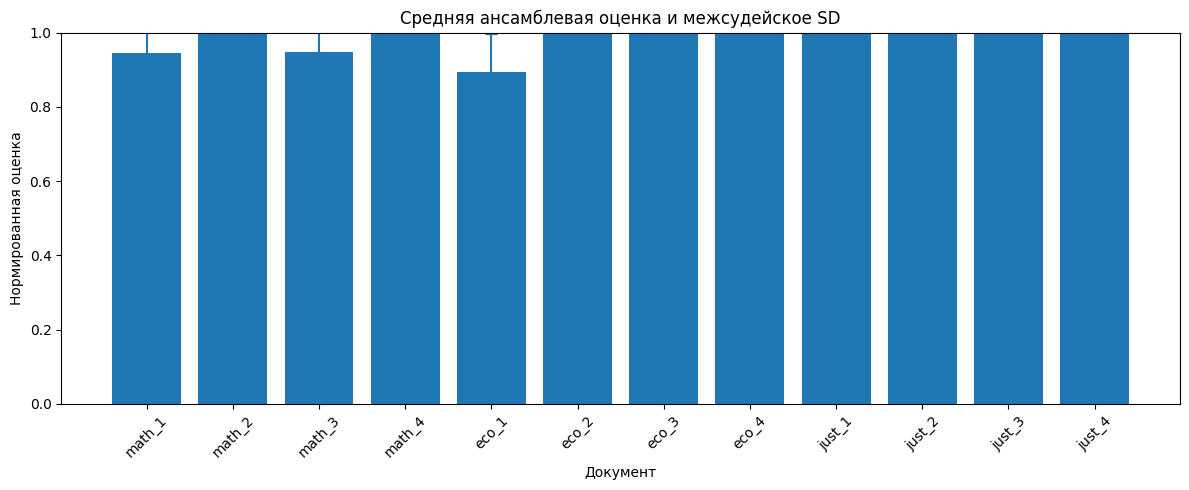

In [ ]:

import matplotlib.pyplot as plt

plot_df = ensemble_summary.sort_values(["domain", "doc_id"]).copy()

plt.figure(figsize=(12, 5))
plt.bar(plot_df["doc_id"], plot_df["ensemble_mean"])
plt.errorbar(
    plot_df["doc_id"],
    plot_df["ensemble_mean"],
    yerr=plot_df["between_judges_sd"].fillna(0),
    fmt="none",
    capsize=4,
)
plt.ylim(0, 1)
plt.ylabel("Нормированная оценка")
plt.xlabel("Документ")
plt.title("Средняя ансамблевая оценка и межсудейское SD")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


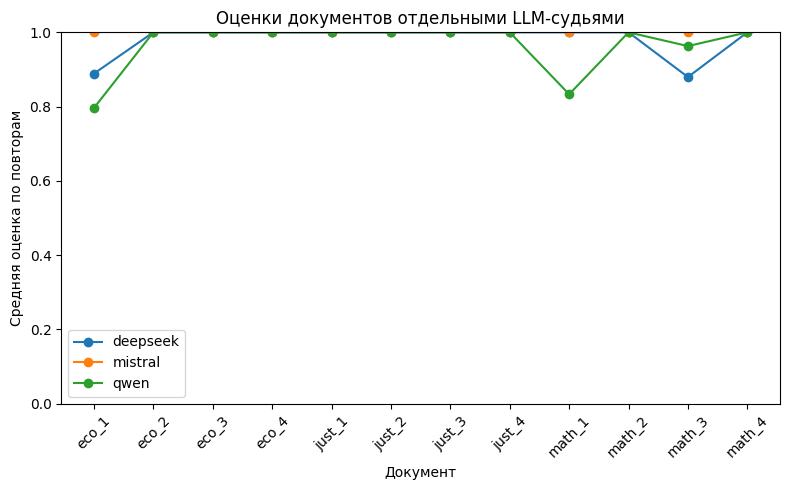

In [ ]:

plt.figure(figsize=(8, 5))
for judge, sub in judge_means.groupby("judge"):
    sub = sub.sort_values("doc_id")
    plt.plot(sub["doc_id"], sub["judge_mean_score"], marker="o", label=judge)

plt.ylim(0, 1)
plt.ylabel("Средняя оценка по повторам")
plt.xlabel("Документ")
plt.title("Оценки документов отдельными LLM-судьями")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


## 18. Экспорт результатов

In [ ]:

tables = {
    "overall_runs.csv": overall_df,
    "nodes_all.csv": nodes_df,
    "judge_means.csv": judge_means,
    "ensemble_summary.csv": ensemble_summary,
    "pairwise_judges.csv": pairwise_df,
    "within_model_stability.csv": within_stability_df,
    "domain_metrics.csv": domain_metrics_df,
    "criterion_metrics.csv": criterion_metrics_df,
    "efficiency.csv": efficiency_df,
    "expansion.csv": expansion_df,
}

for filename, df in tables.items():
    df.to_csv(EXPORT_DIR / filename, index=False, encoding="utf-8-sig")

icc_selected.to_csv(EXPORT_DIR / "icc_overall.csv", index=False, encoding="utf-8-sig")

global_metrics = {
    "krippendorff_alpha_interval": float(alpha_interval),
    "kendall_W": float(kendall_w),
    "friedman_chi_square": float(friedman.statistic),
    "friedman_p_value": float(friedman.pvalue),
    "n_repeats": N_REPEATS,
    "temperature": TEMPERATURE,
    "models": {k: v["model"] for k, v in MODEL_CONFIG.items()},
}
(EXPORT_DIR / "global_metrics.json").write_text(
    json.dumps(global_metrics, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

import shutil
archive_path = shutil.make_archive(
    "/content/llm_judge_results",
    "zip",
    WORK_DIR
)

print("Готово:", archive_path)

from google.colab import files
files.download(archive_path)



## Как интерпретировать основные меры

- **ICC(2,1)** — абсолютная согласованность одного случайно выбранного LLM-судьи с другими судьями.
- **ICC(2,k)** — надежность средней оценки панели из `k=3` судей; для предлагаемого ансамблевого метода особенно важен именно этот показатель.
- **Krippendorff's α (interval)** — согласованность числовых оценок с учетом величины расхождений.
- **Kendall's W** — согласованность ранжирования 12 документов разными моделями.
- **Spearman ρ** — насколько одинаково пара моделей упорядочивает документы.
- **Pearson r** — линейная связь оценок, но сам по себе не является мерой абсолютного согласия.
- **MAE/RMSE** — непосредственная величина числового расхождения двух судей.
- **Friedman test** — проверяет, существует ли систематическая разница уровня оценок между тремя моделями.
- **within-model SD / repeat ICC** — характеризуют воспроизводимость одной и той же модели между независимыми запусками.

Для статьи не стоит выводить все меры в одну таблицу. Основными можно оставить:
`mean ± SD`, `ICC(2,k)`, `Krippendorff α`, `Kendall W`; остальные использовать как дополнительный анализ.
